### Naiver Bayes

[Video Satz von Bayes](https://youtu.be/jTvP5jkq8qc) - [Video Naiver Bayes](https://youtu.be/YeJkWzrsoAI) - [3Blue1Brown zum Satz von Bayes](https://www.youtube.com/watch?v=HZGCoVF3YvM) - [In Colab öffnen](https://colab.research.google.com/github/ktheu/InfoKursN/blob/main/naiverBayes/inhalte/naiver_bayes.ipynb)

Der **naive Bayes-Klassifikator** ist ein einfaches Verfahren des maschinellen Lernens. Er wird vor allem für Texte
eingesetzt:

- Spamfilter (E-Mail ist Spam oder kein Spam)
- Sentiment-Analyse (Bewertung ist positiv oder negativ)
- Themen erkennen (Nachricht gehört zu Sport, Politik oder Wirtschaft)

Er ist schnell, braucht wenige Trainingsdaten und ist leicht zu programmieren. Grundlage ist der **Satz von Bayes**
aus der Wahrscheinlichkeitsrechnung. Das Notebook braucht `scikit-learn` und `matplotlib`, in Google Colab sind sie
installiert.

### Der Satz von Bayes

#### Steve

> Steve ist sehr schüchtern und zurückgezogen, immer hilfsbereit, aber mit wenig Interesse an Menschen oder an der
> realen Welt. Eine sanfte und ordentliche Seele, er hat ein Bedürfnis nach Ordnung und Struktur und eine Leidenschaft
> für Details.

Was ist wahrscheinlicher: Steve ist Bibliothekar oder Steve ist Landwirt? (Das Beispiel stammt von den Psychologen
Daniel Kahneman und Amos Tversky.)

Die meisten tippen auf Bibliothekar, weil die Beschreibung so gut passt. Dabei vergessen sie, wie viele Landwirte es
gibt. Wir schätzen:

- Es gibt etwa 30-mal so viele Landwirte wie Bibliothekare. Das ist die Wahrscheinlichkeit *vor* der Beschreibung,
  der **Prior**: $P(B) = \frac{1}{31}$.
- Die Beschreibung passt auf 30 % der Bibliothekare und auf 4 % der Landwirte. Das ist die **Likelihood**:
  $P(S \mid B) = 0.3$, $P(S \mid L) = 0.04$ ($S$: schüchtern und ordentlich).

Stellen wir uns 10 Bibliothekare und 300 Landwirte vor:

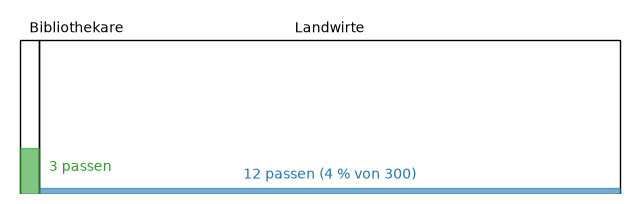

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(8, 2.4))
ax.add_patch(Rectangle((0, 0), 1, 10, fill=False))
ax.add_patch(Rectangle((1, 0), 30, 10, fill=False))
ax.add_patch(Rectangle((0, 0), 1, 3, color='tab:green', alpha=0.6))
ax.add_patch(Rectangle((1, 0), 30, 0.4, color='tab:blue', alpha=0.6))
ax.text(0.5, 10.5, 'Bibliothekare', ha='left')
ax.text(16, 10.5, 'Landwirte', ha='center')
ax.text(1.5, 1.5, '3 passen', color='tab:green')
ax.text(16, 1.0, '12 passen (4 % von 300)', color='tab:blue', ha='center')
ax.set_xlim(-0.5, 31.5)
ax.set_ylim(0, 12)
ax.axis('off')
plt.show()

In [2]:
bibliothekare = 10
landwirte = 300
passen_b = 0.3 * bibliothekare
passen_l = 0.04 * landwirte
print(passen_b, passen_l)
print('P(Bibliothekar | Beschreibung) =', passen_b / (passen_b + passen_l))

3.0 12.0
P(Bibliothekar | Beschreibung) = 0.2


Von den 15 Personen, auf die die Beschreibung passt, sind nur 3 Bibliothekare. Steve ist mit 80 % Wahrscheinlichkeit
Landwirt. Die Beschreibung hat die Wahrscheinlichkeit für *Bibliothekar* zwar von $\frac{1}{31} \approx 3\,\%$ auf
20 % erhöht, aber der Prior war so klein, dass Landwirt wahrscheinlicher bleibt.

#### Die Formel

$H$ sei eine **Hypothese** (Steve ist Bibliothekar), $E$ eine **Beobachtung** (die Beschreibung passt). Dann ist

$$P(H \mid E) = \frac{P(H) \cdot P(E \mid H)}{P(E)} = \frac{P(H) \cdot P(E \mid H)}{P(H) \cdot P(E \mid H) +
P(\neg H) \cdot P(E \mid \neg H)}$$

- $P(H)$: **Prior**, Wahrscheinlichkeit der Hypothese vor der Beobachtung
- $P(E \mid H)$: **Likelihood**, wie gut die Beobachtung zur Hypothese passt
- $P(H \mid E)$: **Posterior**, Wahrscheinlichkeit der Hypothese nach der Beobachtung

Der Nenner ist der Anteil aller Fälle, in denen man $E$ beobachtet. Man kann den Satz so lesen: Neue Beobachtungen
verändern eine Einschätzung (*update belief based on new evidence*).

In [3]:
def bayes(prior, likelihood, likelihood_sonst):
    '''P(H | E) aus P(H), P(E | H) und P(E | nicht H)'''
    zaehler = prior * likelihood
    return zaehler / (zaehler + (1 - prior) * likelihood_sonst)

bayes(1 / 31, 0.3, 0.04)

0.19999999999999998

#### Beispiel: ein medizinischer Test

Eine Krankheit hat 1 % der Bevölkerung. Ein Test erkennt sie bei 90 % der Kranken, schlägt aber auch bei 5 % der
Gesunden fälschlich an. Jemand wird positiv getestet. Wie wahrscheinlich ist er krank?

In [4]:
bayes(0.01, 0.90, 0.05)

0.15384615384615385

Nur etwa 15 %. Unter 1000 Personen sind 10 krank, davon werden 9 positiv getestet. Von den 990 Gesunden werden aber
etwa 50 positiv getestet. Die meisten positiven Tests sind also falscher Alarm. Darum wiederholt man bei seltenen
Krankheiten einen positiven Test.

### Naiver Bayes: Spam erkennen

Ein Spamfilter soll entscheiden, ob eine E-Mail Spam ist. In 100 E-Mails, die von Hand sortiert wurden, wurde gezählt,
in wie vielen die Wörter *kaufen* und *billig* vorkommen:

| | Spam | kein Spam |
|---|---|---|
| Anzahl E-Mails | 25 | 75 |
| enthält *kaufen* | 20 | 5 |
| enthält *billig* | 15 | 10 |

Eine neue E-Mail enthält beide Wörter. Ist sie Spam?

Man bräuchte $P(\text{kaufen und billig} \mid \text{Spam})$. Bei zwei Wörtern könnte man das noch zählen, bei
tausenden Wörtern gibt es aber fast nie zwei E-Mails mit genau denselben Wörtern. Darum nimmt man vereinfachend an,
die Wörter kämen **unabhängig** voneinander vor. Dann darf man die Wahrscheinlichkeiten multiplizieren:

$$P(\text{kaufen und billig} \mid \text{Spam}) = P(\text{kaufen} \mid \text{Spam}) \cdot P(\text{billig} \mid
\text{Spam}) = \tfrac{20}{25} \cdot \tfrac{15}{25}$$

Diese Annahme ist **naiv**, denn wer *kaufen* schreibt, schreibt auch eher *billig*. Daher der Name. Sie funktioniert
trotzdem erstaunlich gut.

In [5]:
spam = 25 * (20 / 25) * (15 / 25)          # erwartete Anzahl Spam-Mails mit beiden Wörtern
kein_spam = 75 * (5 / 75) * (10 / 75)      # erwartete Anzahl normaler Mails mit beiden Wörtern
print(spam, kein_spam)
print('P(Spam | kaufen, billig) =', spam / (spam + kein_spam))

12.0 0.6666666666666666
P(Spam | kaufen, billig) = 0.9473684210526316


Wären die Wörter unabhängig, enthielten 12 der Spam-Mails und $\frac{2}{3}$ der normalen Mails beide Wörter. Die
E-Mail ist also mit etwa 95 % Wahrscheinlichkeit Spam.

Allgemein: Für eine Klasse $K$ (Spam, kein Spam) und die Wörter $w_1, \dots, w_n$ einer E-Mail ist

$$P(K \mid w_1, \dots, w_n) \sim P(K) \cdot P(w_1 \mid K) \cdot P(w_2 \mid K) \cdots P(w_n \mid K)$$

Den Nenner aus dem Satz von Bayes braucht man nicht: Er ist für alle Klassen gleich. Man berechnet das Produkt für
jede Klasse und nimmt die Klasse mit dem größten Wert. Teilt man die Werte durch ihre Summe, erhält man die
Wahrscheinlichkeiten.

### Texte klassifizieren

Wir trainieren einen Klassifikator, der erkennt, ob ein Satz von Hunden, von Katzen oder von etwas anderem handelt.

In [6]:
texte = [
    'Katzen sind niedlich',
    'Hunde sind treu',
    'Katzen mögen Milch',
    'Hunde spielen gern',
    'Milch ist lecker',
    'Ich liebe Hunde',
]
klassen = ['Katze', 'Hund', 'Katze', 'Hund', 'Neutral', 'Hund']

Ein Text wird als **Bag of Words** behandelt (ein Sack voller Wörter): Es zählt nur, welche Wörter wie oft
vorkommen, nicht ihre Reihenfolge. Wir schreiben alles klein und nehmen nur Wörter mit mindestens zwei Zeichen, so wie
es auch scikit-learn macht.

In [7]:
import re
from collections import Counter

def woerter(text):
    return re.findall(r'\b\w\w+\b', text.lower())

anzahl = {k: Counter() for k in set(klassen)}
for text, k in zip(texte, klassen):
    anzahl[k].update(woerter(text))
vokabular = sorted(set(w for text in texte for w in woerter(text)))
print(len(vokabular), vokabular)
anzahl['Hund']

13 ['gern', 'hunde', 'ich', 'ist', 'katzen', 'lecker', 'liebe', 'milch', 'mögen', 'niedlich', 'sind', 'spielen', 'treu']


Counter({'hunde': 3,
         'sind': 1,
         'treu': 1,
         'spielen': 1,
         'gern': 1,
         'ich': 1,
         'liebe': 1})

#### Wahrscheinlichkeiten schätzen

- **Prior:** $P(\text{Hund}) = \frac{3}{6}$, denn 3 von 6 Texten handeln von Hunden.
- **Likelihood:** $P(\text{Wort} \mid \text{Klasse})$ ist der Anteil des Wortes an allen Wörtern der Klasse. In den
  Hunde-Texten stehen 9 Wörter, davon 3-mal *hunde*: $\frac{3}{9}$.

Ein Problem: *milch* kommt in keinem Hunde-Text vor, also wäre $P(\text{milch} \mid \text{Hund}) = 0$, und jeder Text
mit *milch* bekäme für Hund das Produkt 0, egal was sonst darin steht. Deshalb zählt man zu jeder Anzahl 1 dazu
(**Laplace-Glättung**):

$$P(\text{Wort} \mid \text{Klasse}) = \frac{\text{Anzahl des Wortes in der Klasse} + 1}{\text{Anzahl aller Wörter der
Klasse} + \text{Größe des Vokabulars}}$$

Bei 13 Wörtern im Vokabular: $P(\text{hunde} \mid \text{Hund}) = \frac{3 + 1}{9 + 13}$,
$P(\text{milch} \mid \text{Hund}) = \frac{0 + 1}{9 + 13}$.

In [8]:
def p_wort(wort, k):
    gesamt = sum(anzahl[k].values())
    return (anzahl[k][wort] + 1) / (gesamt + len(vokabular))

def prior(k):
    return klassen.count(k) / len(klassen)

print(p_wort('hunde', 'Hund'), 4 / 22)
print(p_wort('milch', 'Hund'), 1 / 22)
print(p_wort('milch', 'Katze'), 2 / 19)

0.18181818181818182 0.18181818181818182
0.045454545454545456 0.045454545454545456
0.10526315789473684 0.10526315789473684


#### Warum Logarithmen?

Bei einem langen Text multipliziert man hunderte kleine Zahlen. Das Ergebnis ist so klein, dass der Computer es nicht
mehr darstellen kann, es wird 0:

In [9]:
import math

print(0.01 ** 1000, 0.02 ** 1000)
print(1000 * math.log(0.01), 1000 * math.log(0.02))

0.0 0.0
-4605.170185988091 -3912.023005428146


Statt die Wahrscheinlichkeiten zu multiplizieren, addiert man deshalb ihre Logarithmen:
$\log(a \cdot b) = \log a + \log b$. Weil der Logarithmus monoton wächst, gewinnt dieselbe Klasse. Am Ende rechnet man
mit $e^x$ zurück. (Damit dabei nichts zu 0 wird, zieht man vorher den größten Wert ab, das ändert die Verhältnisse
nicht.)

In [10]:
def klassifiziere(text):
    wert = {}
    for k in sorted(anzahl):
        wert[k] = math.log(prior(k))
        for w in woerter(text):
            if w in vokabular:           # unbekannte Wörter werden übergangen
                wert[k] += math.log(p_wort(w, k))
    groesster = max(wert.values())
    summe = sum(math.exp(v - groesster) for v in wert.values())
    return {k: round(math.exp(v - groesster) / summe, 4) for k, v in wert.items()}

for text in ['Katzen trinken Milch', 'Hunde sind toll', 'Milch schmeckt']:
    print(f'{text:22}', klassifiziere(text))

Katzen trinken Milch   {'Hund': 0.1312, 'Katze': 0.7035, 'Neutral': 0.1653}
Hunde sind toll        {'Hund': 0.7679, 'Katze': 0.1716, 'Neutral': 0.0605}
Milch schmeckt         {'Hund': 0.289, 'Katze': 0.4461, 'Neutral': 0.2649}


*trinken*, *toll* und *schmeckt* kommen in den Trainingsdaten nicht vor und werden übergangen. *Milch schmeckt*
landet bei Katze: *milch* steht einmal bei Katze (unter 6 Wörtern) und einmal bei Neutral (unter 3 Wörtern), mit
Glättung $\frac{2}{19}$ gegen $\frac{2}{16}$. Neutral hat aber den kleineren Prior ($\frac{1}{6}$ gegen
$\frac{2}{6}$), deshalb gewinnt Katze knapp.

### Dasselbe mit scikit-learn

`CountVectorizer` zählt die Wörter (Bag of Words), `MultinomialNB` ist der naive Bayes-Klassifikator mit
Laplace-Glättung.

In [11]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(texte)
pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out(), index=klassen)

,gern,hunde,ich,ist,katzen,lecker,liebe,milch,mögen,niedlich,sind,spielen,treu
Katze,0,0,0,0,1,0,0,0,0,1,1,0,0
Hund,0,1,0,0,0,0,0,0,0,0,1,0,1
Katze,0,0,0,0,1,0,0,1,1,0,0,0,0
Hund,1,1,0,0,0,0,0,0,0,0,0,1,0
Neutral,0,0,0,1,0,1,0,1,0,0,0,0,0
Hund,0,1,1,0,0,0,1,0,0,0,0,0,0


In [12]:
modell = MultinomialNB()
modell.fit(X, klassen)
print(modell.classes_)
print(modell.class_log_prior_.round(4), [round(math.log(prior(k)), 4) for k in modell.classes_])

['Hund' 'Katze' 'Neutral']
[-0.6931 -1.0986 -1.7918] [-0.6931, -1.0986, -1.7918]


`class_log_prior_` sind die Logarithmen der Priors, z.B. $\ln \frac{3}{6} \approx -0.693$ für Hund.
`feature_log_prob_` enthält die geglätteten $\ln P(\text{Wort} \mid \text{Klasse})$:

In [13]:
log_p = pd.DataFrame(modell.feature_log_prob_, index=modell.classes_, columns=vectorizer.get_feature_names_out())
print(round(log_p.loc['Hund', 'hunde'], 4), round(math.log(4 / 22), 4))
print(round(log_p.loc['Katze', 'milch'], 4), round(math.log(2 / 19), 4))
log_p.round(2)

-1.7047 -1.7047
-2.2513 -2.2513


,gern,hunde,ich,ist,katzen,lecker,liebe,milch,mögen,niedlich,sind,spielen,treu
Hund,-2.40,-1.70,-2.40,-3.09,-3.09,-3.09,-2.40,-3.09,-3.09,-3.09,-2.40,-2.40,-2.40
Katze,-2.94,-2.94,-2.94,-2.94,-1.85,-2.94,-2.94,-2.25,-2.25,-2.25,-2.25,-2.94,-2.94
Neutral,-2.77,-2.77,-2.77,-2.08,-2.77,-2.08,-2.77,-2.08,-2.77,-2.77,-2.77,-2.77,-2.77


In [14]:
neue_texte = ['Katzen trinken Milch', 'Hunde sind toll', 'Milch schmeckt']
X_neu = vectorizer.transform(neue_texte)
print(modell.predict(X_neu))
pd.DataFrame(modell.predict_proba(X_neu), index=neue_texte, columns=modell.classes_).round(4)

['Katze' 'Hund' 'Katze']


,Hund,Katze,Neutral
Katzen trinken Milch,0.1312,0.7035,0.1653
Hunde sind toll,0.7679,0.1716,0.0605
Milch schmeckt,0.2890,0.4461,0.2649


Die Wahrscheinlichkeiten stimmen mit unserer eigenen Rechnung überein. Ein großes Beispiel mit echten Filmkritiken
steht im Notebook **Movie Reviews**.

### Zusammenfassung

- **Satz von Bayes:** $P(H \mid E) = \frac{P(H) \cdot P(E \mid H)}{P(E)}$. Der Prior $P(H)$ wird durch die
  Beobachtung zum Posterior $P(H \mid E)$. Ein kleiner Prior kann eine gut passende Beobachtung überwiegen.
- **Naiver Bayes:** Für jede Klasse $P(K) \cdot \prod P(w_i \mid K)$ berechnen, die größte gewinnt. *Naiv* ist die
  Annahme, die Wörter seien unabhängig.
- Texte werden als **Bag of Words** behandelt. Mit **Laplace-Glättung** (+1) wird kein Wort zur Wahrscheinlichkeit 0.
- Gerechnet wird mit **Logarithmen**, weil die Produkte sonst zu klein werden.